# Від таблиці покупців до зрозумілих груп · версія 2

**240 хв навчальної роботи:** місток із пар 31–32 — 40 хв; пара 33 — 100 хв; пара 34 — 100 хв. Перерви поза цим часом.

Ви аналізуєте інтернет-магазин. Спочатку згадаєте, як перетворити таблицю на карту. Потім навчитеся знаходити групи, пояснювати профілі й відрізняти нетипові точки. Наприкінці матимете невеликий аналіз клієнтів та обґрунтування вибору алгоритму.

**Одна історія:** таблиця → масштабування → SVD/PCA → K-Means → DBSCAN → висновок. PCA створює координати, а кластеризація — мітки. Алгоритми не отримують правильних типів покупців.

**Як працювати.** Відкрийте ipynb у Jupyter зі спільним середовищем кореня python61_ai й виконуйте згори вниз. Прочитайте пояснення, запустіть демо, допишіть власний код завдання. Підказки читайте поступово. HTML і Markdown містять той самий маршрут; код з HTML можна копіювати в ноутбук, у браузері він не виконується. HTML працює офлайн.

**Підготовка до заняття.** Python 3.10+; усі потрібні пакети вже є у requirements.txt репозиторію. Активуйте спільне середовище й запустіть `python -m jupyterlab`. Якщо середовище ще не встановлено, скористайтеся інструкцією в кореневому requirements.txt. Нових залежностей v2 не додає. Встановлення середовища не входить у 240 хв.

**Дані.** 300 синтетичних покупців, шість ознак. Це окрема симуляція за мотивами пояснення про магазин, а не реальна база чи той самий ClientScope з попереднього пакета. Лічильники округлено, відсотки обмежено; допустимі значення не роблять дані справжніми. Seed 42 відтворює приклад; останні знаки чисел можуть залежати від версій бібліотек.

| Час | Частина | Робота |
|---|---|---|
| 0–20 | 31 · SVD | Напрямки, масштаб; завдання 1 |
| 20–40 | 32 · PCA | Карта, дисперсія; завдання 2 |
| 40–65 | 33.1 | Найближчий центр; завдання 3 |
| 65–90 | 33.2 | Вибір k; завдання 4 |
| 90–115 | 33.3 | Профілі; завдання 5 |
| 115–140 | 33.4 | Новий покупець; завдання 6 |
| 140–165 | 34.1 | Ядро, межа, шум; завдання 7 |
| 165–190 | 34.2 | Вибір eps; завдання 8 |
| 190–215 | 34.3 | Півмісяці; завдання 9 |
| 215–240 | 34.4 | Порівняння та звіт; завдання 10 |

## Підготовка даних — виконайте один раз


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import make_moons

# Навчальна симуляція, не справжня історія продажів.
rng = np.random.default_rng(42)
centers = np.array([
    [2, 350, 1, 60, 2, 25],
    [12, 1800, 3, 3, 7, 5],
    [6, 900, 8, 20, 4, 12],
])
spread = np.array([0.7, 140, 1.2, 4, 0.7, 2])
X = np.vstack([rng.normal(c, spread, size=(100, 6)) for c in centers])
# Кількості цілі, дні невід'ємні, відсотки в межах 0..100.
for j in (0, 3, 4):
    X[:, j] = np.maximum(0, np.rint(X[:, j]))
X[:, 1] = np.maximum(1, X[:, 1])
X[:, [2, 5]] = np.clip(X[:, [2, 5]], 0, 100)
columns = ['orders', 'avg_check', 'returns_pct',
           'days_since', 'categories', 'discount_pct']
df = pd.DataFrame(X, columns=columns)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
pca = PCA(n_components=2, svd_solver='full')
X_2d = pca.fit_transform(X_scaled)


def show_map(points, labels=None, title='Карта клієнтів', centers=None):
    fig, ax = plt.subplots(figsize=(7, 4))
    if labels is None:
        ax.scatter(points[:, 0], points[:, 1], s=18, color='steelblue')
    else:
        labels = np.asarray(labels)
        for i, label in enumerate(sorted(set(labels) - {-1})):
            mask = labels == label
            ax.scatter(points[mask, 0], points[mask, 1], s=18,
                       color=plt.get_cmap('tab10')(i % 10), label=f'Група {label}')
        noise = labels == -1
        if noise.any():
            ax.scatter(points[noise, 0], points[noise, 1], s=30,
                       color='gray', marker='x', label='Шум (-1)')
        ax.legend(fontsize=8)
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], marker='X', color='black', s=110)
    ax.set(xlabel='PC1', ylabel='PC2', title=title)
    fig.tight_layout()
    plt.show()

print('Клієнтів і ознак:', df.shape)
print(df.head().round(1).to_string(index=False))


Клієнтів і ознак: (300, 6)
 orders  avg_check  returns_pct  days_since  categories  discount_pct
    2.0      204.4          1.9        64.0         1.0          22.4
    2.0      305.7          1.0        57.0         3.0          26.6
    2.0      507.8          1.6        57.0         2.0          23.1
    3.0      343.0          0.8        57.0         3.0          24.7
    2.0      300.7          1.6        61.0         2.0          25.9


# Блок 1. 31 · Таблиця клієнтів і SVD

**0–20 хв.**

## Навіщо це магазину

Уявіть, що ви аналізуєте інтернет-магазин. Один рядок — один покупець. Шість колонок: замовлення за місяць, середній чек у гривнях, повернення у відсотках, дні після останньої покупки, кількість категорій і середня знижка. Магазин питає: «Чи є тут різні типи покупців?» Спочатку треба підготувати числа й побачити структуру таблиці.

**Факт 1. SVD розкладає матрицю на впорядковані напрямки, але не призначає покупцям групи.**

Схема: таблиця X → напрямки та їхня сила → наближення таблиці меншого рангу.

Покупець А робить 2 замовлення із чеком 350 грн, Б — 12 замовлень із чеком 1800 грн. Якщо в багатьох рядках ці показники зростають разом, це повторювана тенденція. Її можна описати одним напрямком замість двох незалежних описів. SVD шукає такі напрямки математично, але не дає їм бізнес-назв.

Формула `X = U @ diag(s) @ Vt` каже, що таблицю можна зібрати з трьох множників. Рядки `Vt` задають напрямки у просторі ознак, `s` — їхню силу, `U` бере участь у визначенні координат об'єктів. Для стислого опису залишаємо перші r напрямків: координати — `U[:, :r] * s[:r]`, наближена таблиця — ці координати, помножені на `Vt[:r]`.

## Чому спочатку масштаб

Різниця чеків у 1000 грн чисельно більша за різницю в 10 замовлень. Відстані без підготовки можуть майже повністю визначатися гривнями. `StandardScaler` віднімає середнє колонки й ділить на її стандартне відхилення. Покупці зберігають відмінності, але одиниці стають порівнюваними. Це робочий вибір для нашої симуляції; в реальній задачі ваги ознак потребують окремого рішення.

Виконайте початкову комірку. `df` — початкові показники, `X_scaled` — шість масштабованих ознак. Точне відновлення повним SVD повернуло б усі значення з точністю до округлення; усічення залишає частину деталей за бортом.

In [2]:
U, s, Vt = np.linalg.svd(X_scaled, full_matrices=False)
print('Форми:', U.shape, s.shape, Vt.shape)
print('Сила напрямків:', s.round(2))
r = 2
X_approx = (U[:, :r] * s[:r]) @ Vt[:r]
error = np.linalg.norm(X_scaled - X_approx) / np.linalg.norm(X_scaled)
print('Відносна похибка з двома напрямками:', round(error, 3))

Форми: (300, 6) (6,) (6, 6)
Сила напрямків: [37.64 17.7   5.47  4.26  3.39  3.18]
Відносна похибка з двома напрямками: 0.197


## Спробуйте самостійно

**Завдання 1. Залиште три напрямки замість двох.** Збережіть відновлення в `approx3`, надрукуйте форму й відносну похибку. Порівняйте з демонстрацією та поясніть, чому додатковий напрямок не збільшує похибку.

### Підказки

1. Змініть r із 2 на 3; використайте ті самі U, s, Vt.
2. Потрібні перші три колонки U, три числа s і три рядки Vt.
3. Різниця `X_scaled - approx3` — втрачена частина; `np.linalg.norm` вимірює її розмір.
4. Поділіть норму різниці на норму початкової таблиці, як у демо.
5. Відновлення має знову містити шість колонок. Три координати — це стислий опис, а не форма відновленої таблиці.

**Готово, якщо:** Є таблиця 300×6 і числова похибка; ви розрізняєте стислий опис та відновлення.

In [ ]:
# Завдання 1: напишіть власний код за підказками вище.


# Блок 2. 32 · PCA: карта ще не є групуванням

**20–40 хв.**

## Шість ознак на двох осях

**Факт 2. PCA створює координати покупців, а кластеризація згодом створить мітки груп.**

Схема: шість масштабованих ознак → PCA → PC1 і PC2 → карта без готових груп.

PCA повертає нові осі так, щоб перша зберігала найбільшу дисперсію даних, друга — найбільшу залишкову дисперсію перпендикулярно першій. Кожна компонента поєднує початкові ознаки. `PC1` не можна автоматично назвати доходом: треба вивчити внески ознак, а доходу у нас узагалі немає.

PCA працює з центрованою таблицею й може обчислювати осі через SVD. Scaler у нашому прикладі вже відняв середні; PCA також центрує вхід. Важливо: PCA сам не вирівнює масштаби колонок. Саме тому scaler стоїть перед ним.

`fit_transform` знаходить осі й переводить навчальні рядки в нові координати. `transform` переводить нові рядки за вже знайденими осями. Якщо надалі є train/test, навчайте scaler і PCA тільки на train. Сьогодні досліджуємо одну навчальну таблицю без заяв про передбачення майбутньої поведінки.

## Що означає частка дисперсії

`explained_variance_ratio_` показує частку статистичного розкиду, збережену кожною компонентою. Припустімо, сума дорівнює 0.85: це 85% дисперсії, а не 85% правильних груп чи сенсу. Точне число нашого прикладу виведе код. Навіть велика сума не гарантує збереження саме корисних для кластеризації відмінностей.

На карті можна побачити хмари, але PCA нікого не відніс до групи. Наступне питання магазину: «Хто сам розфарбує покупців за схожістю?» Так починається пара 33.

Таблиця: (300, 6) Карта: (300, 2)
Дисперсія: [0.787 0.174]
Разом: 0.961


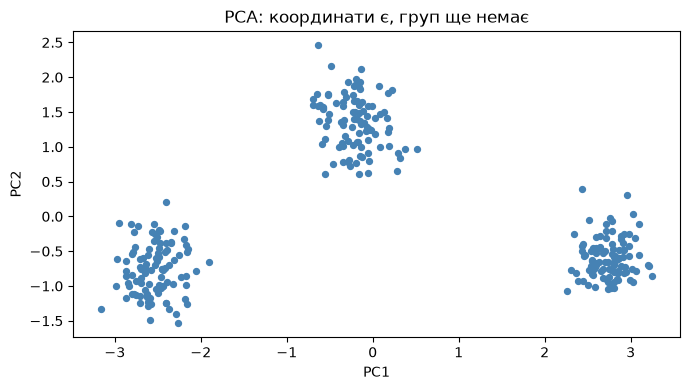

In [4]:
print('Таблиця:', X_scaled.shape, 'Карта:', X_2d.shape)
print('Дисперсія:', pca.explained_variance_ratio_.round(3))
print('Разом:', round(pca.explained_variance_ratio_.sum(), 3))
show_map(X_2d, title='PCA: координати є, груп ще немає')

## Спробуйте самостійно

**Завдання 2. Перевірте ціну стискання.** Створіть окремий PCA із трьома компонентами на шести ознаках. Надрукуйте сумарну частку дисперсії для двох і трьох компонент та приріст. Завершіть речення: «Додаткова компонента зберегла …; це не означає …».

### Підказки

1. Залиште pca і X_2d без змін: карта знадобиться далі.
2. Нову модель назвіть pca3: `PCA(n_components=3, svd_solver='full')`.
3. Використайте X_scaled, а не X_2d: із двох координат не отримати три незалежні компоненти.
4. Після fit_transform складіть елементи explained_variance_ratio_ через `.sum()`.
5. Приріст — різниця двох сум; це не приріст точності.

**Готово, якщо:** Ви порівняли дві суми та відрізняєте дисперсію від точності.

In [ ]:
# Завдання 2: напишіть власний код за підказками вище.


# Блок 3. 33.1 · K-Means: найближчий центр і нове середнє

**40–65 хв.**

## Хто розфарбує карту

**Факт 3. K-Means чергує призначення найближчого центру та перерахунок середнього своїх точок.**

Схема: k центрів → кожній точці найближчий → центри в середні своїх груп → повторення.

Магазин хоче почати з трьох сегментів. `k=3` — наша вимога, а не доведений факт про покупців. Алгоритм розставляє центри, призначає кожного покупця найближчому за евклідовою відстанню, потім пересуває кожен центр у середнє координат його групи. Кроки повторюються до достатньо малих змін або ліміту ітерацій.

На прямій є точки 1, 2, 8, 9 і центри 1 та 9. Перші дві точки ближчі до 1, останні — до 9. Нові центри: (1+2)/2=1.5 і (8+9)/2=8.5. На площині той самий принцип працює для обох координат одночасно. Центр не обов'язково є реальним покупцем: це середні координати.

`fit_predict(X_2d)` навчає модель і повертає номери груп. `cluster_centers_` містить координати центрів. `random_state=42` відтворює запуск у тому самому середовищі. `n_init=10` пробує кілька стартів і залишає найкращий за inertia: це зменшує ризик поганої ініціалізації, але не доводить глобальну оптимальність.

Номер 2 не означає кращого покупця, ніж номер 0. Якщо номери помінялися, групування могло залишитися тим самим.

{0: 100, 1: 100, 2: 100}


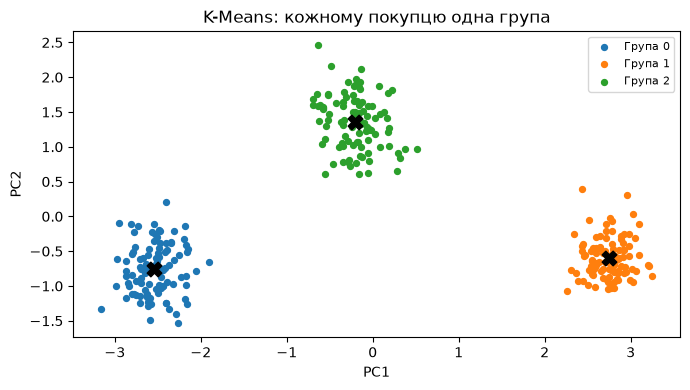

In [6]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_km = km.fit_predict(X_2d)
print(pd.Series(labels_km).value_counts().sort_index().to_dict())
show_map(X_2d, labels_km, 'K-Means: кожному покупцю одна група', km.cluster_centers_)

## Спробуйте самостійно

**Завдання 3. Одна ітерація руками.** Точки: (1,1), (1,3), (8,8), (10,8). Початкові центри: (1,1), (10,8). Передбачте розподіл на папері, потім обчисліть відстані, номери найближчих центрів і нові середні координати.

### Підказки

1. Створіть points і old_centers через np.array.
2. Для однієї точки point вираз `np.linalg.norm(old_centers - point, axis=1)` повертає дві відстані.
3. np.argmin повертає індекс меншої відстані; зберіть індекси в масив assigned.
4. Для групи j візьміть `points[assigned == j].mean(axis=0)`.
5. Тут обидві групи непорожні; загальний алгоритм має окремо обробляти порожню групу.

**Готово, якщо:** Є чотири призначення та два центри; ви можете пояснити обидва кроки.

In [ ]:
# Завдання 3: напишіть власний код за підказками вище.


# Блок 4. 33.2 · Вибираємо k: inertia та silhouette

**65–90 хв.**

## Чи обов'язково існують три типи покупців

**Факт 4. Більше центрів дозволяє зменшити inertia, тому її мінімум не визначає корисне k.**

Схема: кілька k → inertia і silhouette → форма кривих та зміст груп → обґрунтований вибір.

`inertia_` — сума квадратів відстаней до центру своєї групи. Якщо кожній точці дати свій центр, сума стане нульовою. Але 300 сегментів на 300 покупців не допомагають магазину. Теоретичний оптимум inertia не зростає з k; конкретні запуски можуть відхилятися через локальні мінімуми.

Метод ліктя шукає місце, після якого додаткові центри дають менше покращення. Лікоть може бути нечітким. Silhouette порівнює середню відстань до своєї групи a із середньою відстанню до найближчої іншої групи b: (b−a)/max(a,b). Ближче до 1 — група відокремлена, біля 0 — точка на межі, від'ємне — можливе невдале призначення. Це геометрична оцінка, не бізнес-доказ.

Для silhouette потрібно від двох до n−1 груп. Не рахуйте її для однієї групи. Порівнюйте моделі на тих самих точках у тому самому просторі: inertia на шести ознаках і на двох компонентах має різний зміст.

Навіть найкраща silhouette не гарантує найкращої маркетингової кампанії. Після вибору кандидата k ще перевіримо розміри й показники сегментів.

 k  inertia  silhouette
 2  548.244       0.671
 3   52.541       0.839
 4   42.042       0.698
 5   32.674       0.564


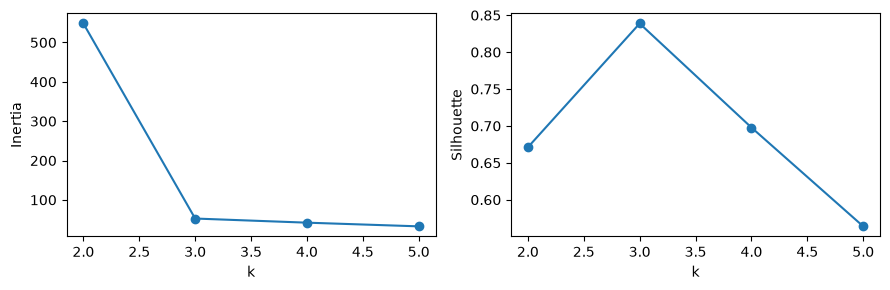

In [8]:
rows_k = []
for k in (2, 3, 4, 5):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_2d)
    rows_k.append({'k': k, 'inertia': model.inertia_,
                   'silhouette': silhouette_score(X_2d, model.labels_)})
k_table = pd.DataFrame(rows_k)
print(k_table.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(k_table.k, k_table.inertia, 'o-')
axes[0].set(xlabel='k', ylabel='Inertia')
axes[1].plot(k_table.k, k_table.silhouette, 'o-')
axes[1].set(xlabel='k', ylabel='Silhouette')
fig.tight_layout()
plt.show()

## Спробуйте самостійно

**Завдання 4. Перевірте k=6.** Навчіть окрему модель на X_2d, надрукуйте inertia й silhouette. Порівняйте з k=3 у таблиці. Двома реченнями поясніть, що сталося з компактністю й чи підтверджує silhouette користь додаткових груп.

### Підказки

1. Змініть лише n_clusters; збережіть n_init=10 і random_state=42.
2. Після fit мітки містяться в labels_.
3. Викличте `silhouette_score(X_2d, model.labels_)`.
4. Для порівняння виберіть рядок `k_table.loc[k_table.k == 3]`.
5. Не пишіть «точність зросла»: правильних відповідей немає. Назвіть конкретну метрику.

**Готово, якщо:** Є обидві метрики та висновок, який не зводиться до «більше груп — краще».

In [ ]:
# Завдання 4: напишіть власний код за підказками вище.


# Блок 5. 33.3 · Профілі груп: повертаємося до гривень

**90–115 хв.**

## Що магазин зробить із кольоровими точками

**Факт 5. Назви сегментів створює людина після аналізу початкових ознак.**

Схема: мітки → приєднати до початкової таблиці → кількість і середні → опис сегмента.

«Кластер 2» нічого не говорить маркетологу. Повернімося до гривень, замовлень і днів. Додамо мітку кожному рядку, порахуємо кількість покупців і середні значення. Тоді можна сказати: «Ця група купує частіше й має більший середній чек».

Не називайте людей багатими на основі покупок в одному магазині: середній чек не є доходом. Високий відсоток повернень також не доводить зловживань. Профіль описує спостережені показники, а бізнес-дія залишається гіпотезою.

`groupby('cluster')` збирає рядки з однаковою міткою. `.agg(...)` обчислює статистики. Працюємо з копією: номер кластера не повинен стати ознакою наступного навчання.

Центри на PCA-карті вимірюються в компонентах, а не у гривнях. Для середнього чека агрегуємо початкову таблицю, замість того щоб вгадувати зміст координат центру. Середнє — лише початок аналізу: за потреби вивчіть медіану, розкид і окремі рядки.

In [10]:
profiled = df.assign(cluster=labels_km)
profiles = profiled.groupby('cluster').agg(
    clients=('orders', 'size'), orders=('orders', 'mean'),
    avg_check=('avg_check', 'mean'), days_since=('days_since', 'mean'))
print(profiles.round(1).to_string())

         clients  orders  avg_check  days_since
cluster                                        
0            100    11.9     1791.2         3.9
1            100     2.0      338.1        60.2
2            100     5.9      895.9        19.7


## Спробуйте самостійно

**Завдання 5. Знайдіть групу з найбільшою середньою частотою замовлень.** Виведіть її номер, кількість покупців і середній чек. Запропонуйте обережну назву та одну дію магазину з поясненням.

### Підказки

1. У profiles колонка orders уже містить середні значення.
2. `profiles['orders'].idxmax()` повертає індекс максимуму — номер групи.
3. Візьміть рядок через `profiles.loc[номер]`.
4. Назвіть спостережувану поведінку, наприклад «часті покупки». Не вгадуйте вік, професію чи дохід.
5. Дію сформулюйте як перевірювану пропозицію, а не гарантію результату.

**Готово, якщо:** Назва групи й запропонована дія підкріплені числами, а не кольором.

In [ ]:
# Завдання 5: напишіть власний код за підказками вище.


# Блок 6. 33.4 · Новий покупець: transform і predict

**115–140 хв.**

## Магазин отримав новий рядок

**Факт 6. Новий рядок проходить ті самі scaler та PCA, потім K-Means обирає найближчий центр.**

Схема: новий рядок → scaler.transform → pca.transform → km.predict → група.

Новий покупець має 11 замовлень і чек 1700 грн. Масштаб ознак, осі та центри вже знайдені. Не навчайте новий scaler на одному рядку: всі його ознаки перетворяться на нулі. Не перенавчайте окремо PCA: нові осі перестануть відповідати старим центрам.

`predict` повертає найближчу групу. `transform` у K-Means показує відстані до всіх центрів. Навіть дуже нетиповий покупець отримає номер: штатної мітки «не знаю» чи «шум» тут немає. Сам номер не доводить близькості до групи.

K-Means зручний для компактних груп. Для двох центрів геометрична межа призначення — пряма на площині; вигнута група може бути розрізана. Після checkpoint перевіримо іншу логіку: обходити щільні області й за потреби залишати точки поза групами.

In [12]:
new_customer = pd.DataFrame([[11, 1700, 2, 4, 6, 6]], columns=columns)
new_2d = pca.transform(scaler.transform(new_customer))
print('Група:', km.predict(new_2d))
print('Відстані:', km.transform(new_2d).round(2))

Група: [0]
Відстані: [[0.49 4.82 2.92]]


## Спробуйте самостійно

**Завдання 6. Перевірте нетипового покупця.** Рядок: [40, 12000, 60, 0, 20, 0], ті самі колонки. Отримайте групу та найменшу відстань до центру. Порівняйте зі звичайним покупцем із демо. Поясніть, чому мітка не доводить схожості.

### Підказки

1. Створіть DataFrame з одним рядком і columns=columns.
2. Використайте transform двічі; fit тут не потрібен.
3. `km.transform(...)` дає масив 1×3; `.min()` — відстань до найближчого центру.
4. Віддалена точка все одно має найближчий центр. Не вигадуйте довільний поріг «поганого клієнта».

**Готово, якщо:** Ви не перенавчаєте підготовку на одному рядку та пояснюєте межу predict.

In [ ]:
# Завдання 6: напишіть власний код за підказками вище.


# Блок 7. 34.1 · DBSCAN: ядро, межа та шум

**140–165 хв.**

## Чи можна не призначати групу

**Факт 7. DBSCAN з'єднує щільні сусідства й може залишити точки з міткою -1.**

Схема: коло eps → достатньо сусідів → ядра з'єднуються → межові приєднуються → решта шум.

DBSCAN питає: «Чи достатньо поруч схожих точок?» `eps` — радіус сусідства у вибраному просторі. `min_samples` — мінімальна кількість точок у ньому, включно із самою точкою у scikit-learn.

Ядрова точка має достатньо сусідів. Межова не має власної достатньої густоти, але перебуває біля ядрової. Шум не належить жодному кластеру. Ланцюжок ядер може пройти вздовж вигнутої форми. Межові точки приєднуються, але самі не продовжують цей ланцюжок.

Приклад на прямій: 0.0, 0.1, 0.2, 0.4, 2.0; eps=0.21, min_samples=3. Точка 0.1 бачить 0.0, себе й 0.2 — це вже ядро. Точка 0.4 бачить себе й 0.2: власної густоти замало, але 0.2 є ядром, тому 0.4 може приєднатися. Біля 2.0 нікого немає — це шум. Перевірте всі ролі в завданні.

У магазині eps=0.3 вимірюється у PCA-координатах, а не у гривнях. Мітка -1 означає рідкісне оточення за поточних параметрів, а не шахрайство. Число кластерів не задаємо, але параметри щільності все одно обираємо ми.

Груп: 3
Шум: 4


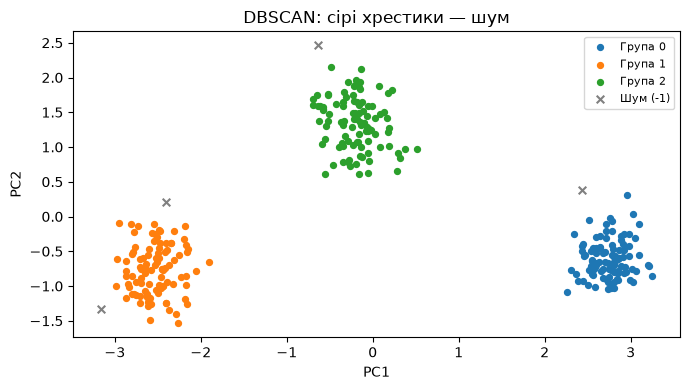

In [14]:
db = DBSCAN(eps=0.3, min_samples=5).fit(X_2d)
labels_db = db.labels_
print('Груп:', len(set(labels_db) - {-1}))
print('Шум:', int((labels_db == -1).sum()))
show_map(X_2d, labels_db, 'DBSCAN: сірі хрестики — шум')

## Спробуйте самостійно

**Завдання 7. Розрізніть три ролі.** Запустіть DBSCAN на п'яти точках із пояснення. Надрукуйте мітки та індекси ядер. Підпишіть роль кожної точки й поясніть, чому 0.4 у кластері, хоча сама не ядро.

### Підказки

1. Дані мають форму 5×1: `np.array([[0.0], [0.1], [0.2], [0.4], [2.0]])`.
2. Використайте DBSCAN(eps=0.21, min_samples=3).fit(...).
3. Індекси ядер лежать у core_sample_indices_.
4. Порядок перевірки: мітка -1 → шум; індекс у ядерних → ядро; інакше → межа.
5. Порахуйте сусідів біля 0.2 і 0.4 вручну, включаючи самі точки.

**Готово, якщо:** Є приклад усіх трьох ролей; сама точка врахована в min_samples.

In [ ]:
# Завдання 7: напишіть власний код за підказками вище.


# Блок 8. 34.2 · Вибір eps: радіус змінює результат

**165–190 хв.**

## Одного красивого запуску замало

**Факт 8. Малий eps може розсипати групи на шум, а великий — з'єднати різні групи.**

Схема: фіксуємо простір і min_samples → кілька eps → групи та частка шуму → перевірка карти.

Радіус 0.1 на масштабованій карті й 0.1 у сирих гривнях — різні експерименти. Після зміни масштабу, числа ознак чи PCA не переносіть eps автоматично. Зміна min_samples теж змінює вимогу до щільності.

Ми не прагнемо будь-що прибрати шум: великий радіус може зробити одну групу з усіх покупців. Читайте кількість кластерів і шуму разом із картою та профілями. Шукайте діапазон параметрів зі зрозумілим, достатньо стійким результатом.

Графік k-відстаней дає підказку. Для кожної точки беремо відстань до min_samples-го найближчого сусіда з урахуванням самої точки, потім сортуємо. Різкий підйом інколи підказує кандидат eps; це не гарантія. У коді передаємо X_2d явно в kneighbors(X_2d), щоб власна точка враховувалася, як у DBSCAN.

За сильно різних щільностей може не існувати одного вдалого глобального eps. У високій розмірності близькість також стає складнішою. Поганий результат може означати невідповідний простір чи метод, а не лише «потрібно довше крутити параметри».

In [16]:
rows_eps = []
for eps in (0.1, 0.3, 0.5, 1.0, 3.0):
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_2d)
    rows_eps.append({'eps': eps, 'clusters': len(set(labels) - {-1}),
                     'noise_pct': 100 * np.mean(labels == -1)})
eps_table = pd.DataFrame(rows_eps)
print(eps_table.round(1).to_string(index=False))

 eps  clusters  noise_pct
 0.1        12       41.7
 0.3         3        1.3
 0.5         3        0.0
 1.0         3        0.0
 3.0         1        0.0

## Спробуйте самостійно

**Завдання 8. Побудуйте графік 5-відстаней.** Знайдіть п'ять сусідів кожної точки, візьміть останню відстань у рядку, відсортуйте та побудуйте лінію. Додайте горизонтальну лінію eps=0.3 й порівняйте з таблицею.

### Підказки

1. Навчіть NearestNeighbors(n_neighbors=5) на X_2d.
2. `distances, indices = model.kneighbors(X_2d)` повертає дві матриці; потрібна перша.
3. `distances[:, -1]` — відстань до п'ятого сусіда із самою точкою; відсортуйте через np.sort.
4. Використайте plt.plot, plt.axhline(0.3) та plt.show.
5. Осі: точки за зростанням відстані та відстань. Не трактуйте місце злому як гарантований оптимум.

**Готово, якщо:** Є 300 відстаней та висновок із перевіркою і шуму, і кількості груп.

In [ ]:
# Завдання 8: напишіть власний код за підказками вище.


# Блок 9. 34.3 · Півмісяці: форма важливіша за центр

**190–215 хв.**

## Чи завжди DBSCAN кращий

**Факт 9. DBSCAN може відстежити вигнуту щільну групу, яку K-Means розріже за близькістю до центрів.**

Схема: дві вигнуті хмари → центри або ланцюжки ядер → два різні розбиття.

На хвилину замінимо магазин геометричним стендом. Два півмісяці не схожі на круглі компактні хмари. Навіть із правильним k=2 K-Means може розрізати кожен півмісяць. DBSCAN із придатним радіусом проходить уздовж вигину через ядрові сусідства.

make_moons повертає точки й відомі генератору мітки. Тут правильні мітки є, тому після навчання порахуємо ARI — збіг розбиттів із поправкою на випадковість. ARI=1 означає однаковий поділ, навіть якщо номери помінялися. Біля 0 — рівень, близький до випадкового за цією мірою. Відомі мітки не додаємо до ознак і не передаємо в навчання.

Вдалий результат на півмісяцях не доводить перемогу DBSCAN всюди. У реальних даних щільності можуть відрізнятися, а області — торкатися. Висновок завжди стосується конкретних даних, простору та параметрів.

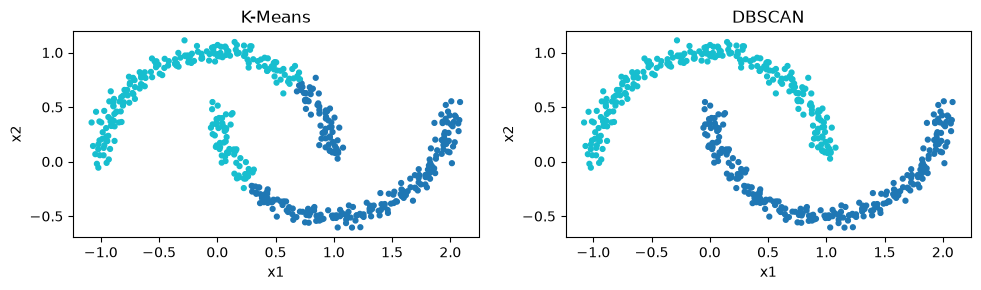

ARI K-Means: 0.253
ARI DBSCAN: 1.0


In [18]:
moons, moon_truth = make_moons(n_samples=500, noise=0.05, random_state=42)
moon_km = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(moons)
moon_db = DBSCAN(eps=0.2, min_samples=5).fit_predict(moons)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, labels, title in zip(axes, (moon_km, moon_db), ('K-Means', 'DBSCAN')):
    ax.scatter(moons[:, 0], moons[:, 1], c=labels, cmap='tab10', s=12)
    ax.set(title=title, xlabel='x1', ylabel='x2')
fig.tight_layout()
plt.show()
print('ARI K-Means:', round(adjusted_rand_score(moon_truth, moon_km), 3))
print('ARI DBSCAN:', round(adjusted_rand_score(moon_truth, moon_db), 3))

## Спробуйте самостійно

**Завдання 9. Зробіть eps надто малим і надто великим.** Повторіть DBSCAN на тих самих moons для eps=0.05 і eps=0.5. Надрукуйте кількість груп, шуму й ARI. Порівняйте з eps=0.2 та поясніть, що сталося.

### Підказки

1. Не генеруйте нові точки: порівнюємо ті самі дані.
2. Зробіть цикл `for radius in (0.05, 0.5)`.
3. Кількість кластерів: `len(set(labels) - {-1})`; шуму: `int((labels == -1).sum())`.
4. ARI рахуйте з moon_truth. Тут шум залишається міткою -1, а його кількість звітуємо окремо.
5. Сформулюйте, що робить малий радіус і як великий змінює зв'язність хмар.

**Готово, якщо:** Ви показали, як зміна радіуса допомагає відстежити форму або псує результат.

In [ ]:
# Завдання 9: напишіть власний код за підказками вище.


# Блок 10. 34.4 · Порівняння й висновок магазину

**215–240 хв.**

## Що ми можемо порадити

**Факт 10. Корисність сегментації перевіряють профілями, покриттям і припущеннями, а не лише кольоровою картою.**

Схема: одна таблиця → два алгоритми → групи, шум, профілі → висновок із межами застосування.

Повернімося до тих самих покупців. K-Means має три групи й призначення для всіх. DBSCAN повертає знайдені щільні області й може відкинути шум. Номери кластерів між алгоритмами не узгоджені: група 0 одного не обов'язково відповідає групі 0 іншого.

Для silhouette DBSCAN спочатку виключимо шум. Потрібні принаймні дві групи та більше точок, ніж груп. Якщо умова не виконана, повернемо «не визначено», а не нуль. Така оцінка описує лише залишені точки, тому не оголошуйте її прямою перемогою над K-Means на всіх рядках.

Для порівняння на однакових рядках окремо порахуємо silhouette K-Means на тих покупцях, яких DBSCAN не відкинув. Усе одно повідомляємо покриття. Це геометрична перевірка; користь для магазину потребує інтерпретації профілів і бізнес-експерименту.

PCA перед кластеризацією необов'язковий. Карта зручна для навчання, але перед використанням порівняйте її з кластеризацією шести масштабованих ознак. Велика частка дисперсії сама не доводить збереження груп.

У DBSCAN зі scikit-learn немає штатного predict для нових покупців. Можна перенавчати модель на оновленій таблиці або обґрунтувати окреме правило віднесення до ядер. Другий варіант уже не є вбудованим передбаченням DBSCAN.

In [20]:
def safe_silhouette(points, labels):
    labels = np.asarray(labels)
    n_groups = len(np.unique(labels))
    if not 2 <= n_groups < len(labels):
        return None
    return float(silhouette_score(points, labels))

keep = labels_db != -1
print('DBSCAN, частка охоплених:', round(keep.mean(), 3))
print('K-Means, усі:', safe_silhouette(X_2d, labels_km))
print('DBSCAN, без шуму:', safe_silhouette(X_2d[keep], labels_db[keep]))
print('K-Means, ті самі рядки:', safe_silhouette(X_2d[keep], labels_km[keep]))
print('DBSCAN має predict:', hasattr(db, 'predict'))
print(df.assign(cluster=labels_db).groupby('cluster')[['orders', 'avg_check']].mean().round(1))

DBSCAN, частка охоплених: 0.987
K-Means, усі: 0.8387775377756211
DBSCAN, без шуму: 0.8431303783987892
K-Means, ті самі рядки: 0.8431303783987892
DBSCAN має predict: False
         orders  avg_check
cluster                   
-1          7.8     1333.9
 0          2.0      335.4
 1         11.9     1789.4
 2          5.9      895.2


## Спробуйте самостійно

**Завдання 10. Перевірте повну таблицю й напишіть висновок.** Навчіть K-Means із трьома групами на X_scaled. Порахуйте ARI між цим розбиттям і labels_km на карті. Складіть звіт із чотирьох речень: що зберігає PCA; які профілі знайшли; як DBSCAN поводиться із шумом; що перевірити перед використанням сегментів.

### Підказки

1. Створіть новий KMeans із n_clusters=3, n_init=10, random_state=42, не перезаписуйте km.
2. Передайте X_scaled у fit_predict, збережіть full_labels.
3. `adjusted_rand_score(labels_km, full_labels)` — узгодженість двох розбиттів, а не точність щодо невідомих справжніх типів.
4. Візьміть показники з profiles та кількість шуму з labels_db.
5. Закінчіть обмеженням: дані синтетичні, користь потребує перевірки на реальній поведінці.

**Готово, якщо:** Є порівняння двох просторів і звіт, який відрізняє результат від бізнес-гіпотези.

In [ ]:
# Завдання 10: напишіть власний код за підказками вище.



## Підсумок і самоперевірка

Закінчіть фрази: SVD допомагає…; PCA повертає…; K-Means потребує…; DBSCAN може… . Який із методів має штатний predict? Чи означає шум шахрайство? Чи обов'язково робити PCA перед кластеризацією?

**Де перечитати:** блоки 1–2 про напрямки й карту; 3–6 про центри; 7–10 про щільність і перевірку. Попередній маршрут залишається в корені репозиторію: PythonAI_Author_Lesson33_Lesson34.md.

## Додаткова практика після заняття

Змініть seed симуляції, повторіть аналіз та порівняйте профілі. Чи залишаються висновки стійкими? Час цієї необов'язкової роботи не включено до 240 хв.
